# 04逻辑回归：从得分到概率
## 问题：线性回归不能做分类
线性回归公式：
$$ z = \boldsymbol w^T \boldsymbol x + b $$
$z$ 的取值范围是 $(-\infty,+\infty)$，不适合分类任务：
1. 输出值可以大于 1 或者小于 0，无法解释为概率
2. 异常样本对拟合结果影响很大
3. 如果直接搭配 MSE 损失，损失函数非凸，优化容易卡在局部最小值

> ✅ 解决方案：Sigmoid 函数，把任意实数映射到 $(0,1)$，作为正类的预测概率。

## Sigmoid（Logistic）函数
$$ \sigma(z) = \frac{1}{1+e^{-z}} $$
性质：
* 值域：$\sigma(z) \in (0,1)$
    * $z=0$ 时，$\sigma(z)=0.5$
    * $z>0 \Rightarrow p>0.5$，预测类别 $y=1$
    * $z<0 \Rightarrow p<0.5$，预测类别 $y=0$
* 单调递增；$z$ 绝对值很大时进入饱和区，梯度趋近 0

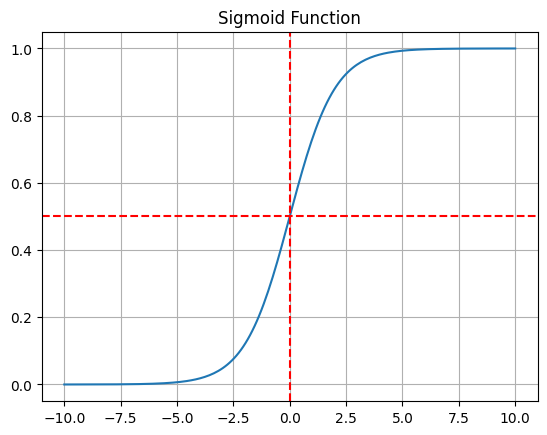

In [1]:
import numpy as np
import matplotlib.pyplot as plt
z = np.linspace(-10,10,200)
s = 1/(1+np.exp(-z))
plt.plot(z,s)
plt.grid(True)
plt.axhline(0.5,c='r',ls='--')
plt.axvline(0,c='r',ls='--')
plt.title("Sigmoid Function")
plt.show()


## 逻辑回归模型表达式
$$ \hat p = \sigma(\boldsymbol w^T \boldsymbol x + b) = \frac{1}{1+e^{-(\boldsymbol w^T \boldsymbol x + b)}} $$
> 💡重点：逻辑回归名字带“回归”，本质是二分类线性分类器


## 决策边界
边界满足：
$$ \boldsymbol w^T \boldsymbol x + b = 0 $$
* 1 个特征：分界点（一个数值）
* 2 个特征：分界直线
* 多个特征：分界超平面
> ✅ 逻辑回归的决策边界一定是线性的。

逻辑回归是线性分类器，决策边界一定是直线/超平面